In [35]:
# coding: utf-8

__author__ = "Gouvenou Pierre, Van Gennip Simon"

# Import necessary libraries

import json
import numpy as np
import matplotlib.pyplot as plt
import datetime
import xarray as xr
import os, glob,sys
import pandas as pd
from configparser import ConfigParser
import getpass
import ftputil
from tqdm import tqdm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import pearsonr
import matplotlib

# Read information from the configuration file

config_object = ConfigParser()
config_object.read("config_base.ini")
config_info = config_object['CONFIG_BASE']
MODELS = config_info["MODELS"].split(',')
LON_MIN = int(config_info["lon_min"])
LON_MAX = int(config_info["lon_max"])
LAT_MIN = int(config_info["lat_min"])
LAT_MAX = int(config_info["lat_max"])
DEPTH = int(config_info["depth"])
DATE1 = config_info["DATE_start"]
DATE2 = config_info["DATE_end"]
PROJECT = config_info["PROJECT"]
EXP_NAME = config_info["EXP_NAME"]
USERNAME = config_info["username"]
DIR_WORK = config_info["dir_work"]
DIR_IN = config_info["dir_in"]
REMOTE = bool(config_info["remote"])
COPERNICUS_DRIFTER = bool(config_info["copernicus_drifter"])
DRIFT_TIME = int(config_info["DRIFT_TIME"])
AdvectionDiffusion_type = config_info["AdvectionDiffusion_type"]
nb_repeats = int(config_info["nb_repeats"])


# Print configuration information

print("MODELS : ",MODELS)
print("Region : ",LON_MIN,", ",LON_MAX,", ",LAT_MIN,", ",LAT_MAX)
print("From : ",DATE1," to ",DATE2)

# Add a directory to the Python sys path

sys.path.append("src/")

# Import custom functions from local module

from Drift_Tools import ReturnUVlist, ExtractSurface, match_elements, StringRegion, DispDirAndLength,  SeparationDistance, TrajDistBetweenTimesteps, SepDistanceEachTimestep, LiuScore2, shift360, DriftersInZoneInPeriod, coord2index, DriftersInZoneInPeriod_remote

from Functions import Retrieve_traj_files,Retrieve_drifters_traj,Traj_filter,Report_card_plot,Retrieve_traj_files_diff,proba_density_2D_SK

# Create an output directory path

STR_REGION = StringRegion(LON_MIN,LON_MAX,LAT_MIN,LAT_MAX)
DIR_OUT=DIR_WORK+"DRIFT/"+PROJECT+'/'+EXP_NAME+'/ZONE_'+STR_REGION+'/'
print("Dir out : ",DIR_OUT)

# Retrieve the starting date and the ending date

DD1=np.int32(DATE1[:2])
MM1=np.int32(DATE1[2:4])
YYYY1=np.int32(DATE1[4:])
DD2=np.int32(DATE2[:2])
MM2=np.int32(DATE2[2:4])
YYYY2=np.int32(DATE2[4:])
DATE_START = datetime.date(YYYY1, MM1, DD1)
STR_DATE_START= DATE_START.strftime('%Y-%m-%d')
DATE_START_MIN1 = DATE_START-datetime.timedelta(days=1)
DATE_END=datetime.date(YYYY2, MM2, DD2)
STR_DATE_END=DATE_END.strftime('%Y-%m-%d')
DATE_END_PLUS1 = DATE_END+datetime.timedelta(days=1)
DATE_END_PLUS_DRIFT_TIME =  DATE_END+datetime.timedelta(days=DRIFT_TIME+1)
STR_DATE_END_PLUS_DRIFT_TIME=DATE_END_PLUS_DRIFT_TIME.strftime('%Y-%m-%d')
T_DRIFT = (DATE_END_PLUS_DRIFT_TIME -DATE_START).days




if AdvectionDiffusion_type == "K_smag":
    traj_lon_smag,traj_lat_smag,traj_time_smag = Retrieve_traj_files_diff(MODELS,DIR_OUT,AdvectionDiffusion_type)
elif AdvectionDiffusion_type == "AdvectionDiffusionM1":
    traj_lon_M1,traj_lat_M1,traj_time_M1 = Retrieve_traj_files_diff(MODELS,DIR_OUT,AdvectionDiffusion_type)
traj_lon,traj_lat,traj_time = Retrieve_traj_files(MODELS,DIR_OUT)

fout_driftersZone = 'Drifters_'+STR_REGION+'_'+STR_DATE_START+'_'+STR_DATE_END_PLUS_DRIFT_TIME+'.csv'
dir_drifters = DIR_OUT+'/DRIFTERS/'


outfile2 = dir_drifters+fout_driftersZone

traj_drifter_lon,traj_drifter_lat,traj_drifter_date,traj_drifter_time,traj_drifter_id,nb_drifters_temp = Retrieve_drifters_traj(outfile2,T_DRIFT,REMOTE,COPERNICUS_DRIFTER)

# Plot Drifter's trajectories

dir_plot = DIR_OUT+'PLOT/'


if not os.path.exists(dir_plot):
    print('\ncreate folder : ', dir_plot)
    # Create directory where to store results:
    os.makedirs(dir_plot)

drifter_lon,drifter_lat = Traj_filter(REMOTE,COPERNICUS_DRIFTER, DRIFT_TIME,traj_drifter_lon,traj_drifter_lat, traj_lon,traj_lat)





MODELS :  ['GLO12V4', 'GLOBC']
Region :  -19 ,  5 ,  26 ,  56
From :  15012019  to  20012019
Dir out :  /data/rd_exchange/pgouvenou/DRIFT/project_test/test_coper_dri/ZONE_19W5E-26N56N/
loading  /data/rd_exchange/pgouvenou/DRIFT/project_test/test_coper_dri/ZONE_19W5E-26N56N//DRIFTERS/Drifters_19W5E-26N56N_2019-01-15_2019-01-24.csv
   Unnamed: 0       id        date      time        lat     lon
0         0.0  4101599  2019-01-15  12:00:00  51.459000 -10.110
1         0.0  4101599  2019-01-15  13:00:00  51.455002 -10.102
2         0.0  4101599  2019-01-15  14:00:00  51.449001 -10.098
3         0.0  4101599  2019-01-15  15:00:00  51.445000 -10.098
4         0.0  4101599  2019-01-15  16:00:00  51.442001 -10.101
Unnamed: 0    float64
id              int64
date           object
time           object
lat           float64
lon           float64
dtype: object


In [36]:
matplotlib.use('Agg')
%matplotlib inline

In [37]:
if COPERNICUS_DRIFTER:
    t_s = 24
else:
    t_s = 4

In [38]:
dir_plot = DIR_OUT+'PLOT/'


if not os.path.exists(dir_plot):
    print('\ncreate folder : ', dir_plot)
    # Create directory where to store results:
    os.makedirs(dir_plot)


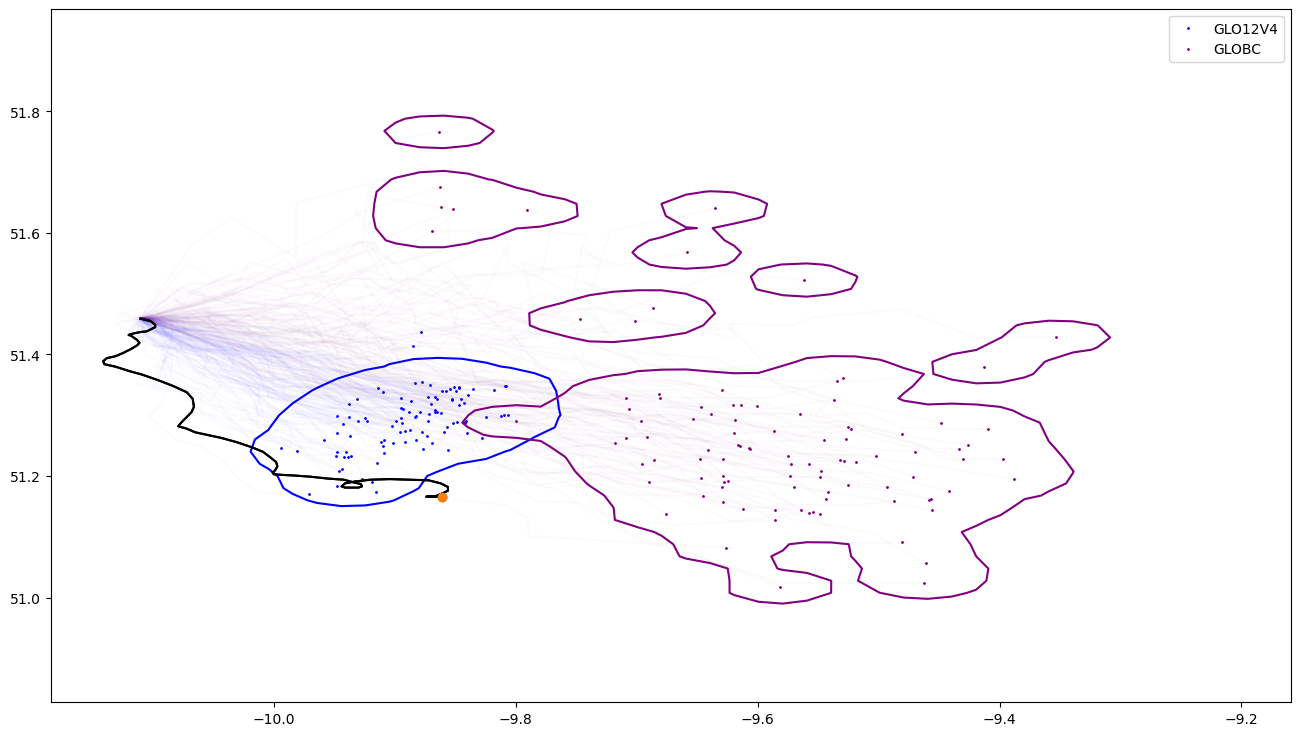

In [39]:

id = 0
day = 0
config_object = ConfigParser()
config_object.read(DIR_IN+"src/config_products.ini")
colors = []
for MODEL in MODELS:
    run_info = config_object[MODEL]
    colors.append(run_info["color"])

fig,ax = plt.subplots(figsize = (16,9))
CS = []
for MODELid in range (len(MODELS)):
    m1 = traj_lon_smag[MODELid,day,id::nb_drifters_temp].T[-1]
    m2 = traj_lat_smag[MODELid,day,id::nb_drifters_temp].T[-1]


    xmin = m1.min()-0.2
    xmax = m1.max()+0.2
    ymin = m2.min()-0.2
    ymax = m2.max()+0.2
    resx = 1/50
    resy = 1/50
    datax = m1
    datay = m2

    
    ax.plot(m1,m2,'o',c = colors[MODELid],ms = 1,label = MODELS[MODELid])
    ax.plot(traj_lon_smag[MODELid,day,id::nb_drifters_temp].T,traj_lat_smag[MODELid,day,id::nb_drifters_temp].T,c=colors[MODELid],alpha = 0.02)
        
    Xi, Yi, Zi , LVL = proba_density_2D_SK(m1, m2, resx, resy, xlim = [xmin,xmax], ylim = [ymin, ymax], quantiles = [0.95],
                    metric = 'haversine', bandwidth = 5, nsample = nb_repeats + 1, kernel = 'epanechnikov',
                    periodx = 360)  
    CS.append(ax.contour(Xi,Yi,Zi,levels = LVL,colors = colors[MODELid]))
    #ax.plot(traj_lon_smag[MODELid,day,id::nb_drifters_temp].T[-1],traj_lat_smag[MODELid,day,id::nb_drifters_temp].T[-1],'o',c = colors[MODELid],ms = 1)
    #ax.plot(traj_lon_smag[MODELid,day,id::nb_drifters_temp].T,traj_lat_smag[MODELid,day,id::nb_drifters_temp].T,c=colors[MODELid],alpha = 0.02)
    #confidence_ellipse(traj_lon_smag[MODELid,day,id::nb_drifters_temp].T[-1],traj_lat_smag[MODELid,day,id::nb_drifters_temp].T[-1],ax, n_std=3,label=r'$3\sigma$ '+MODELS[MODELid],edgecolor = colors[MODELid])
    ax.plot(traj_drifter_lon[id][0+day*t_s:DRIFT_TIME*t_s+1+day*t_s],traj_drifter_lat[id][0+day*t_s:DRIFT_TIME*t_s+1+day*t_s],c='k')
    ax.plot(traj_drifter_lon[id][0+day*t_s:DRIFT_TIME*t_s+1+day*t_s][-1],traj_drifter_lat[id][0+day*t_s:DRIFT_TIME*24+1+day*t_s][-1],'o')
    

    plt.legend()


plt.savefig(DIR_OUT+'PLOT/figure_particles_95_kde.png',dpi = 400)

In [44]:
from shapely.geometry import Polygon, Point

In [45]:
from importlib import reload

reload(sys.modules['Functions'])
from Functions import proba_density_2D_SK

In [47]:
matplotlib.interactive(False)
in_out_array = np.zeros((traj_lon_smag.shape[0],traj_lon_smag.shape[1],int(traj_lon_smag.shape[2]/nb_repeats)))
prop_tot = []
area_contour = []
for i in range (0,traj_lon_smag.shape[0]):
    in_poly = 0
    tot = 0
    area_contour_int = []
    for day in tqdm(range(traj_lon_smag.shape[1])):
        area_contour_int1 = []
        for dri in range(int(traj_lon_smag.shape[2]/nb_repeats)):
            m1 = traj_lon_smag[i,day,dri::nb_drifters_temp].T[-1]
            m2 = traj_lat_smag[i,day,dri::nb_drifters_temp].T[-1]
            xmin = m1.min()-0.2
            xmax = m1.max()+0.2
            ymin = m2.min()-0.2
            ymax = m2.max()+0.2
            resx = 1/50
            resy = 1/50
            datax = m1
            datay = m2
            Xi, Yi, Zi , LVL = proba_density_2D_SK(m1, m2, resx, resy, xlim = [xmin,xmax], ylim = [ymin, ymax],
                                                   quantiles = [0.95],metric = 'haversine', bandwidth = 5, 
                                                   nsample = 1001, kernel = 'epanechnikov',periodx = 360)  

            contour = ax.contour(Xi,Yi,Zi,levels = LVL,colors = colors[i]).allsegs[0]
            pt = Point((traj_drifter_lon[dri][0+day*t_s:DRIFT_TIME*t_s+1+day*t_s][-1],
                        traj_drifter_lat[dri][0+day*t_s:DRIFT_TIME*t_s+1+day*t_s][-1]))
            area = 0
            for k in range(len(contour)):
                poly = Polygon(np.vstack([contour[k][:,0],contour[k][:,1]]).T)
                area+= poly.area
                if poly.contains(pt):
                    in_poly+=1
                    in_out_array[i,day,dri] = 1 
            tot+=1
            area_contour_int1.append(area)
        area_contour_int.append(area_contour_int1)
    print("Proportion of drifter in 95% kde contour for model '", MODELS[i],"' : ",round(in_poly/tot*100,2),"%")
    prop_tot.append(round(in_poly/tot*100,2))
    area_contour.append(area_contour_int)       
        


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 18.81it/s]


Proportion of drifter in 95% kde contour for model ' GLO12V4 ' :  23.81 %


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 13.64it/s]

Proportion of drifter in 95% kde contour for model ' GLOBC ' :  23.81 %


In [48]:
matplotlib.use('Agg')
%matplotlib inline

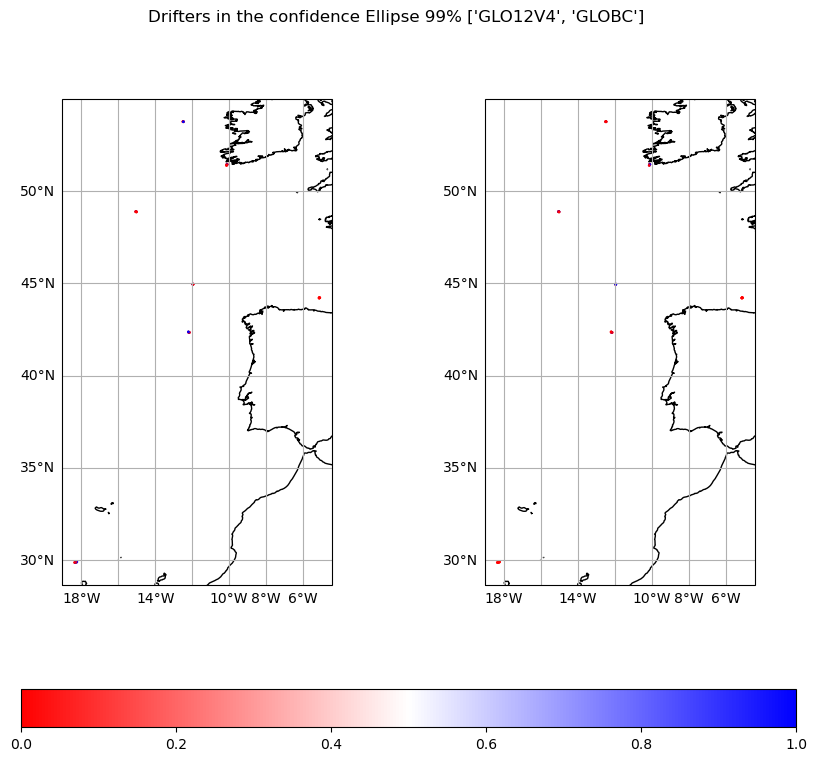

In [51]:
fig,axs = plt.subplots(figsize = (5*len(MODELS),9),ncols=len(MODELS),subplot_kw={'projection': ccrs.PlateCarree()})
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        axs.coastlines()
        axs.add_feature(cfeature.LAND)
        gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Drifters in the confidence Ellipse 99% ' + str(MODELS) ,fontsize = 12)
        if REMOTE:
            
            im = axs.scatter(traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
        else :
            
            im = axs.scatter(traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
    
    fig.colorbar(im, ax=axs,orientation = 'horizontal')    
else : 
    for i in range(len(MODELS)):
        axs[i].coastlines()
        gl = axs[i].gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Drifters in the confidence Ellipse 99% ' + str(MODELS) ,fontsize = 12)
        if REMOTE:
            
            im = axs[i].scatter(traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
        else :
            
            im = axs[i].scatter(traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
    
    fig.colorbar(im, ax=axs.ravel().tolist(),orientation = 'horizontal')
plt.savefig(DIR_OUT+'PLOT/confidence_contour_inout.png',dpi = 400)

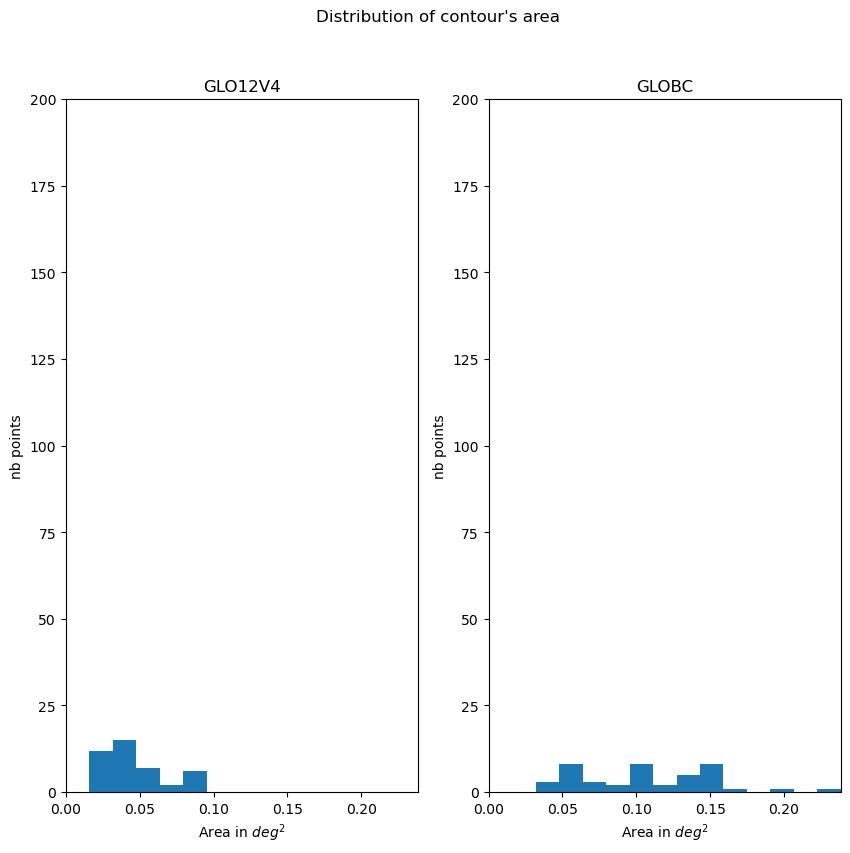

In [52]:

fig,axs = plt.subplots(figsize = (5*len(MODELS),9),ncols=len(MODELS))
n_sep = []
x_sep = []
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        fig.suptitle("Distribution of contour's area ",fontsize = 12)
        axs.set_title(MODELS[i])
        n1, x1, _ = axs.hist( np.array(area_contour[i]).flatten(),bins = 15,range=(0,np.max(np.array(area_contour).flatten())))
        axs.set_xlim([0,np.max(np.array(area_contour).flatten())])
        axs.set_ylim([0,200])    
        n_sep.append(n1)
        x_sep.append(x1)
        axs[i].set_xlabel('Area in $deg^{2}$')
        axs[i].set_ylabel('nb points')

else : 
    for i in range(len(MODELS)):
        fig.suptitle("Distribution of contour's area ",fontsize = 12)
        axs[i].set_title(MODELS[i])
        n1, x1, _ = axs[i].hist( np.array(area_contour[i]).flatten(),bins = 15,range=(0,np.max(np.array(area_contour).flatten())))
        axs[i].set_xlim([0,np.max(np.array(area_contour).flatten())])
        axs[i].set_ylim([0,200])
        n_sep.append(n1)
        x_sep.append(x1)
        axs[i].set_xlabel('Area in $deg^{2}$')
        axs[i].set_ylabel('nb points')

plt.savefig(DIR_OUT+'PLOT/area_contour.png',dpi = 400)

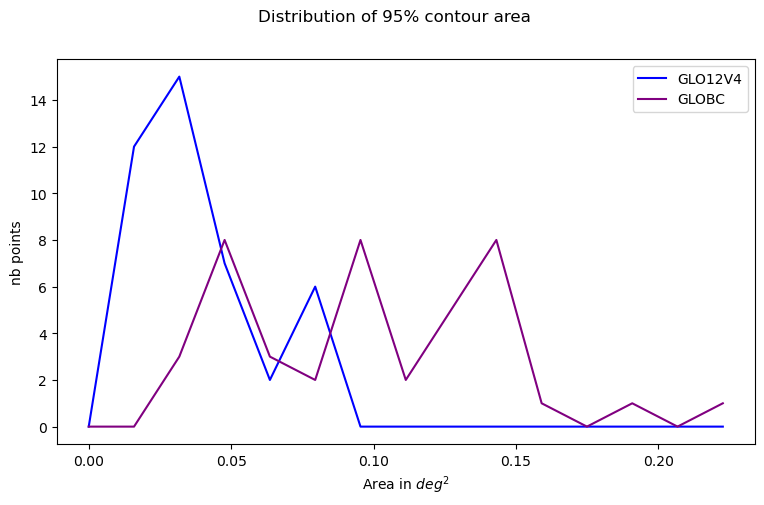

In [53]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Distribution of 95% contour area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_sep[i][:-1],n_sep[i],label =MODELS[i],color = colors[i])


#axs.plot([0,np.max(x_sep)],[0,np.max(n_sep)],'--',c='k')
axs.legend()
axs.set_xlabel('Area in $deg^{2}$')
axs.set_ylabel('nb points')
#plt.grid()

plt.savefig(DIR_OUT+'PLOT/area_contour_curves.png',dpi = 400)

In [55]:
cell_size = 1
grid = np.meshgrid(np.linspace(LON_MIN,LON_MAX,int((LON_MAX - LON_MIN )/cell_size)+ 1),np.linspace(LAT_MIN,LAT_MAX,int((LAT_MAX - LAT_MIN )/cell_size)+ 1))

In [56]:
sum_traj = np.zeros(grid[0].shape)
sum_elli = np.array([np.zeros(grid[0].shape)]*len(MODELS))

for mod in range (in_out_array.shape[0]):
    for i in range (grid[0].shape[0]-1):
        for j in range (grid[0].shape[1]-1):
            
            #print(grid[0][i,j],grid[0][i,j]+cell_size)
            #print(grid[1][i,j],grid[1][i,j]+cell_size)
            indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::t_s][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lon[:,::t_s][:,:-3][:,:in_out_array.shape[1]]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::t_s][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lat[:,::t_s][:,:-3][:,:in_out_array.shape[1]]<grid[1][i,j]+cell_size)))
            if indice[0].shape[0]!= 0:
                sum_traj[i,j] = indice[0].shape[0]
                sum_elli[mod,i,j] = np.sum(in_out_array[mod][indice[1],indice[0]])
                

In [57]:
sum_traj_tot = np.zeros(grid[0].shape)

for i in range (grid[0].shape[0]-1):
    for j in range (grid[0].shape[1]-1):
        
        #print(grid[0][i,j],grid[0][i,j]+cell_size)
        #print(grid[1][i,j],grid[1][i,j]+cell_size)
        indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::t_s][:,:-3])*(traj_drifter_lon[:,::t_s][:,:-3]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::t_s][:,:-3])*(traj_drifter_lat[:,::t_s][:,:-3]<grid[1][i,j]+cell_size)))
        if indice[0].shape[0]!= 0:
            sum_traj_tot[i,j] = indice[0].shape[0]
            

In [58]:
sum_traj_tot[np.where(sum_traj_tot==0)] = np.nan

/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


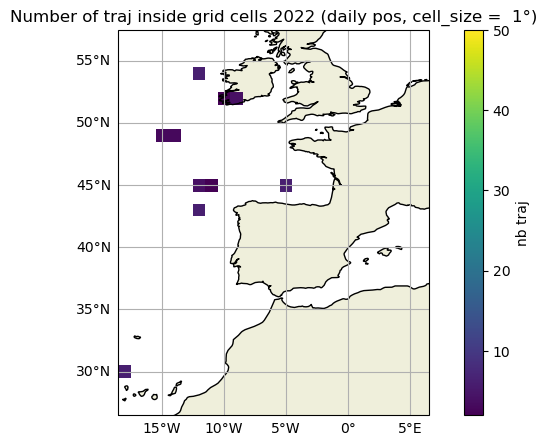

In [60]:
fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
plt.title('Number of traj inside grid cells 2022 (daily pos, cell_size =  '+str(cell_size)+'°)')
cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_traj_tot,vmax = 50)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
axs.coastlines()
axs.add_feature(cfeature.LAND)
plt.colorbar(cb,label =  'nb traj')
plt.savefig(DIR_OUT+'PLOT/number_of_traj_in_grid_cells.png',dpi = 400)

/tmp/ipykernel_5192/3911542050.py:25: RuntimeWarning: invalid value encountered in divide
  cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
/tmp/ipykernel_5192/3911542050.py:25: RuntimeWarning: invalid value encountered in divide
  cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)


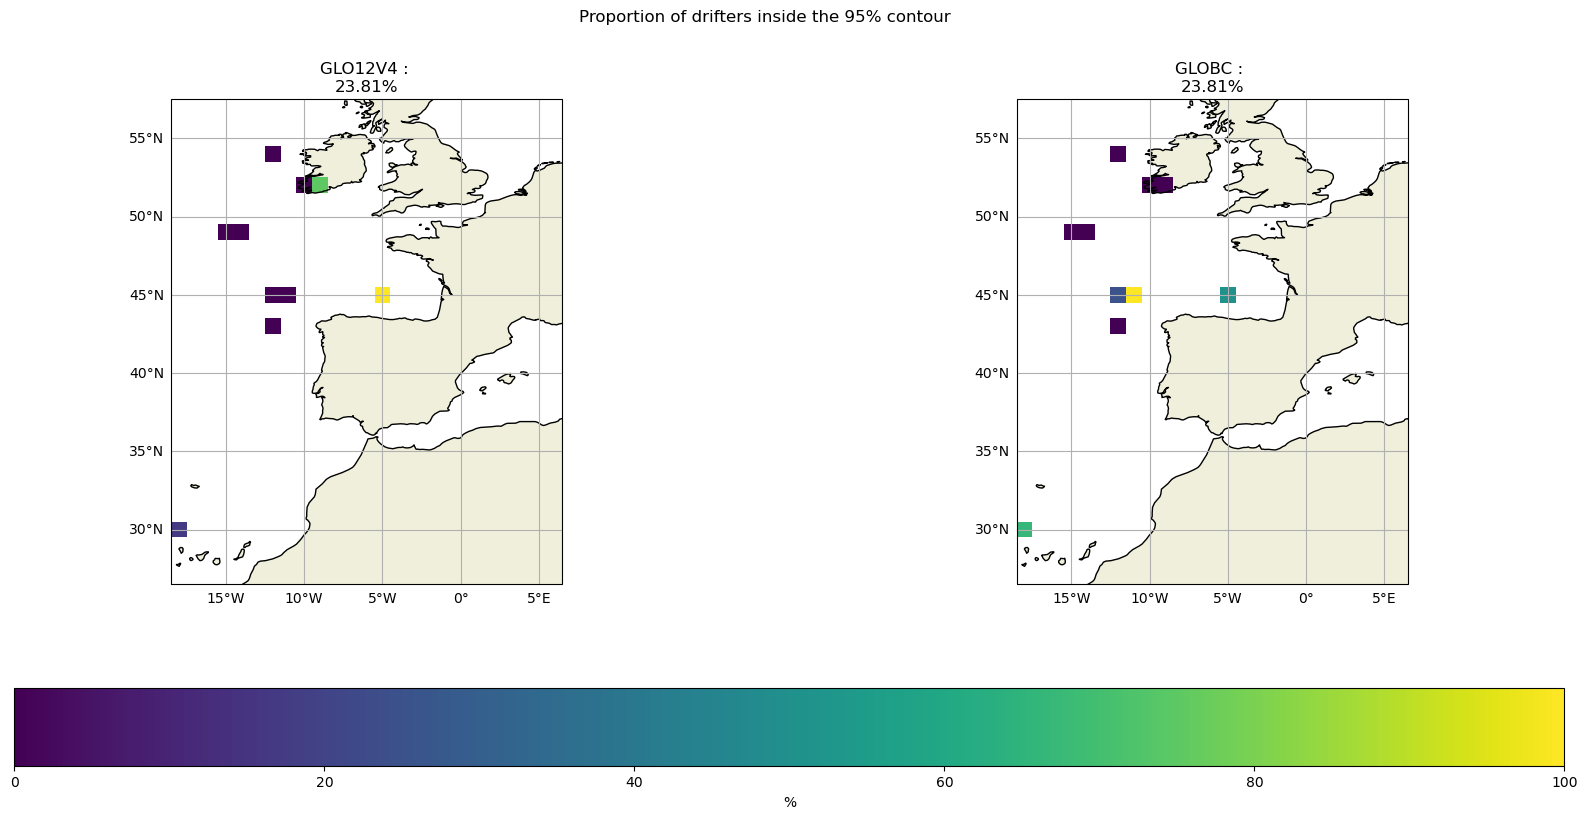

In [61]:
fig,axs = plt.subplots(figsize = (10*len(MODELS),9),ncols=len(MODELS),subplot_kw={'projection': ccrs.PlateCarree()})
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        axs.coastlines()
        axs.add_feature(cfeature.LAND)
        gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Proportion of drifters inside the 95% contour',fontsize = 12)
        axs.set_title(MODELS[i]+' : \n'+str(prop_tot[i])+"%")
        cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
        axs.add_feature(cfeature.LAND)
    fig.colorbar(cb, ax=axs,orientation = 'horizontal',label="%")

    
else :   
    for i in range(len(MODELS)):
        axs[i].coastlines()
        axs[i].add_feature(cfeature.LAND)
        gl = axs[i].gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Proportion of drifters inside the 95% contour',fontsize = 12)
        axs[i].set_title(MODELS[i]+' : \n'+str(prop_tot[i])+"%")
        cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
        axs[i].add_feature(cfeature.LAND)

    fig.colorbar(cb, ax=axs.ravel().tolist(),orientation = 'horizontal',label="%")
plt.savefig(DIR_OUT+'PLOT/map_proportion_contour.png',dpi = 400)

/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
/tmp/ipykernel_5192/3798861592.py:9: RuntimeWarning: invalid value encountered in divide
  cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,(sum_elli[0]-sum_elli[-1])/sum_traj * 100,vmin = -100,vmax = 100,cmap = "bwr")


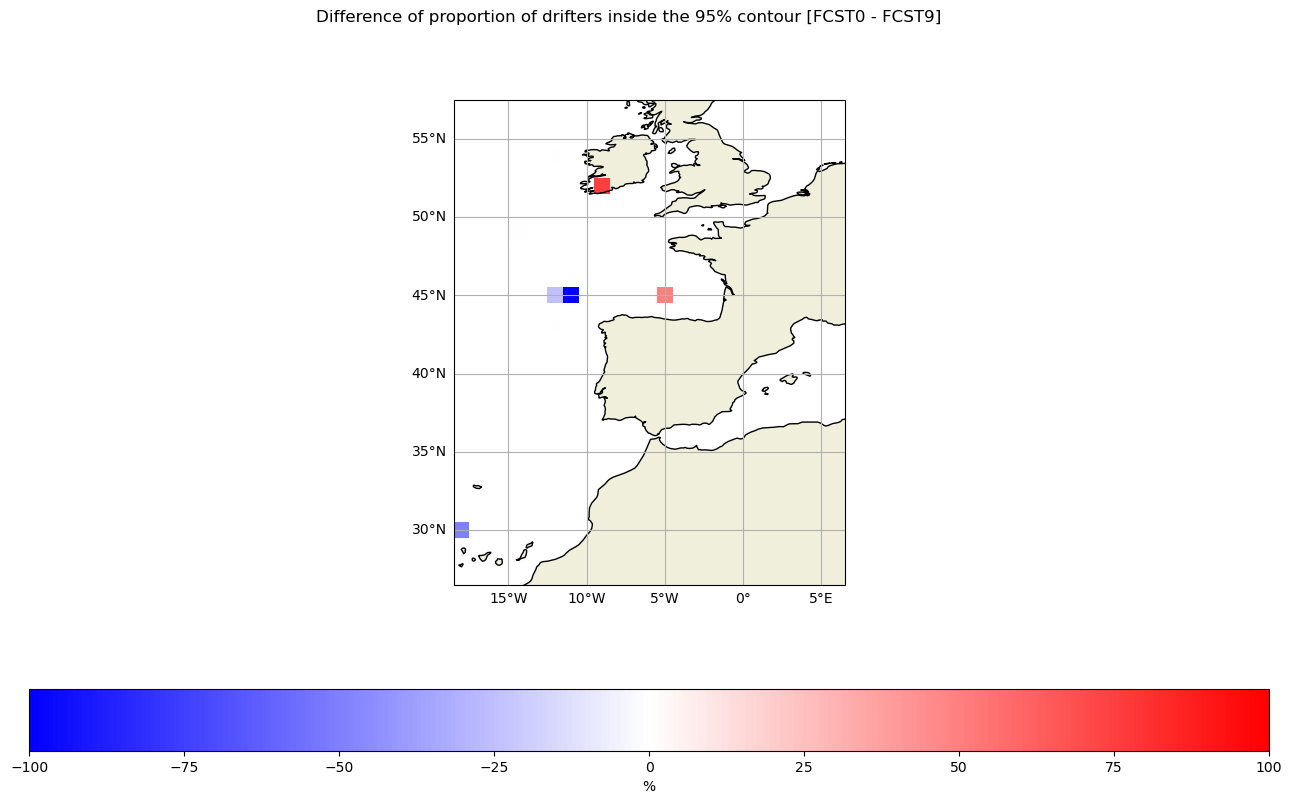

In [62]:

fig,axs = plt.subplots(figsize = (16,9),ncols=1,subplot_kw={'projection': ccrs.PlateCarree()},facecolor = 'white')

axs.coastlines()
axs.add_feature(cfeature.LAND)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
fig.suptitle('Difference of proportion of drifters inside the 95% contour [FCST0 - FCST9]',fontsize = 12)
cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,(sum_elli[0]-sum_elli[-1])/sum_traj * 100,vmin = -100,vmax = 100,cmap = "bwr")
axs.add_feature(cfeature.LAND)

fig.colorbar(cb, ax=axs,orientation = 'horizontal',label="%")
plt.savefig(DIR_OUT+'PLOT/map_proportion_contour_diff_FCST0_FCST9.png',dpi = 400)        